# 09 — Replacing a model: champion against challenger

Every notebook so far asked one question: *is this model good enough?* A
replacement raises a second one, and a governance review usually cares about it
more: **is it better than the model already in production — and better for
whom?**

A challenger can clear every absolute threshold and still be worse than the
champion it replaces. Since 0.7.0 the gate measures that too. Hand it the
champion, and it scores both models on the same rows and adds seven comparison
checks to the report.

This notebook replaces a credit scorecard. The new model is genuinely better
overall — and a data-pipeline bug has made it markedly worse for one sales
channel, in a way the headline number cannot show. Then it walks through the
traps that make a comparison *confidently* wrong rather than merely failing:
an inverted label encoding, a pickle from an older library version, and an
artifact that is not the one that was approved.

In [1]:
import tempfile
import warnings
from pathlib import Path
from unittest import mock

import joblib
import numpy as np
import pandas as pd
import sklearn.base
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

import bdp_model_gate
from bdp_model_gate import (
    Champion,
    ComparisonConfig,
    GateConfig,
    ModelGate,
    PerformanceConfig,
    StructuredGateContext,
)
from bdp_model_gate.champion import sha256_of
from bdp_model_gate.exceptions import GateConfigurationError
from bdp_model_gate.structured import default_structured_checks

warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
warnings.filterwarnings("ignore", message="IProgress not found")  # shap's progress bar
print("bdp-model-gate", bdp_model_gate.__version__)
registry = Path(tempfile.mkdtemp(prefix="model-registry-"))

bdp-model-gate 0.7.0


## The book

Personal loans, sold through three channels. Branch and online customers
default on one pattern — utilisation and tenure matter most. **Broker-sourced
loans default on another**: for them the debt ratio is nearly everything.
About one loan in seven comes through a broker.

In [2]:
rng = np.random.default_rng(2026)


def book(n):
    channel = rng.choice(["branch", "online", "broker"], n, p=[0.45, 0.40, 0.15])
    income = rng.lognormal(11.3, 0.45, n)
    debt_ratio = rng.beta(2, 5, n)
    tenure = rng.integers(0, 25, n).astype(float)
    utilisation = rng.beta(2, 3, n)
    broker = channel == "broker"
    z = np.where(
        broker,
        -1.0 + 7.0 * (debt_ratio - 0.28) - 0.03 * tenure,
        -2.2 + 1.0 * debt_ratio + 4.5 * utilisation - 0.07 * tenure - 0.9 * (np.log(income) - 11.3),
    )
    default = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
    X = pd.DataFrame(
        {
            "income": income.round(0),
            "debt_ratio": debt_ratio.round(3),
            "tenure": tenure,
            "utilisation": utilisation.round(3),
            "broker": broker.astype(float),
        }
    )
    protected = pd.DataFrame({"region": rng.choice(["north", "south"], n)})
    return X, default, protected, channel


X_2025, y_2025, _, _ = book(6000)  # last year's book: the champion was trained on it
X_2026, y_2026, _, channel_2026 = book(8000)  # this year's: the challenger's training data
X_val, y_val, protected_val, channel_val = book(5000)  # held out, this year
print(f"default rate {y_val.mean():.1%}, broker share {(channel_val == 'broker').mean():.1%}")

default rate 31.2%, broker share 13.7%


## The champion, v3

A logistic scorecard on four features, approved last year and sitting in the
model registry. The registry records its SHA-256 at approval time — that
digest is what the gate will pin.

In [3]:
V3_FEATURES = ["income", "debt_ratio", "tenure", "broker"]
v3 = LogisticRegression(max_iter=2000).fit(X_2025[V3_FEATURES], y_2025)

v3_path = registry / "scorecard_v3.joblib"
joblib.dump(v3, v3_path)
approved_sha256 = sha256_of(v3_path)
print(v3_path.name, approved_sha256[:16], "…")

scorecard_v3.joblib a2716189c89ec760 …


## The challenger, v4

A gradient-boosted model on five features, trained on this year's book. What
nobody on the team knows yet: a join in the feature pipeline silently dropped
every broker-sourced loan from its training data.

In [4]:
dropped_by_the_join = channel_2026 == "broker"
v4 = HistGradientBoostingClassifier(max_iter=200, random_state=0).fit(
    X_2026[~dropped_by_the_join], y_2026[~dropped_by_the_join]
)
print(f"v4 trained on {(~dropped_by_the_join).sum()} of {len(X_2026)} rows")

v4 trained on 6810 of 8000 rows


## Gate the challenger, against the champion

The champion is loaded the way a pipeline would load it — from the registry
file, with its approved hash pinned. The hash is checked **before** anything is
unpickled, and the provenance goes into the report.

In [5]:
champion = Champion.from_file(v3_path, sha256=approved_sha256)
champion.describe()

{'name': 'champion',
 'source': 'file',
 'loader': 'joblib',
 'path': '/var/folders/b0/2m_10_k95pv414965fb1ndjr0000gn/T/model-registry-xy2_x37k/scorecard_v3.joblib',
 'sha256': 'a2716189c89ec760f49b658ae29026b01e4cdc9d849e333643339be5995f741f',
 'sha256_pinned': True,
 'size_bytes': 1183}

`X_val` carries the union of both models' features. The champion reads its
four from `feature_names_in_`; the challenger gets all five.

Two settings on the comparison: a **Brier guardrail** with an absolute margin,
so the challenger cannot buy AUC with its calibration; and the `broker` column
as a **segment**, because the business already thinks of the book by channel.

In [6]:
config = GateConfig(
    performance=PerformanceConfig(metric="roc_auc", min_score=0.65),
    comparison=ComparisonConfig(guardrails={"brier": 0.01}, segments=["broker"]),
)


def gate(model, champion, config=config):
    context = StructuredGateContext(
        model=model,
        X=X_val,
        y_true=y_val,
        y_pred=model.predict_proba(X_val)[:, 1],
        protected_df=protected_val,
        champion=champion,
        task="binary",
    )
    return ModelGate(checks=default_structured_checks(config), config=config).run(context)


report = gate(v4, champion)
print(report.summary())

Gate status: BLOCKED (30450ms, binary)
  roc_auc: 0.6978
  vs champion: roc_auc 0.6978 against 0.6517, Δ +0.0461 [+0.0292, +0.0636] -> improved
  validation: 0 flag(s)
  comparison: 4 flag(s)
  performance: 0 flag(s)
  compliance: 0 flag(s)
  security: 1 flag(s)
  fairness: 0 flag(s)


In [7]:
def comparison_table(report):
    rows = [
        (r.check_name, r.flag, "blocks" if (r.blocking and not r.is_ok) else "", r.detail)
        for r in report.by_category("comparison")
    ]
    with pd.option_context("display.max_colwidth", 150):
        return pd.DataFrame(rows, columns=["check", "flag", "", "detail"])


comparison_table(report)

,check,flag,,detail
0,comparison_integrity,OK,,"champion scorecard_v3.joblib (joblib, sha256 a..."
1,challenger_performance,OK,,"roc_auc (higher is better): challenger 0.6978,..."
2,challenger_guardrails,OK,,"brier: challenger 0.2019, champion 0.2018, Δ -..."
3,subgroup_regression,OK,,region: no group is materially worse off. Wors...
4,subgroup_regression,SUBGROUP_WORSE,,broker: challenger is clearly worse for 1 (-0....
5,fairness_delta,UNCERTAIN,,region: demographic parity difference challeng...
6,fairness_delta,UNCERTAIN,,region: equal opportunity (TPR) gap challenger...
7,decision_churn,UNCERTAIN,,21.8% of decisions change: 11.2% fixed (champi...
8,operational_delta,NOT_APPLICABLE,,no matching operational measurements — supply ...


## Reading it

The headline is unambiguous: v4's AUC is higher, and the whole interval on
the *difference* sits above zero. On the metric everyone looks at, v4 wins.

Two findings say why that is not the end of the review:

- **`subgroup_regression`** — for broker-sourced loans the challenger is
  *clearly worse*, by about a tenth of AUC, with an interval that excludes
  zero even after widening for the number of groups compared. The aggregate
  improvement is real; it is made entirely of branch and online customers.
- **`decision_churn`** — roughly one decision in five changes, and the breaks
  (loans the champion decided correctly that v4 now gets wrong) nearly cancel
  the fixes: the net gain is under one point. The break rate sits right on its
  10% tolerance, so the check reports `UNCERTAIN` rather than guessing which
  side of it the truth is on. A large churn for a small net gain is a model that
  is *different*, not simply better.

Both are non-blocking: a segment that got worse may be an acceptable trade, and
only someone who owns the broker channel can say. The gate's job is to make
sure that someone sees it — which a single AUC would never have done.

The two `fairness_delta` results are `UNCERTAIN` for the same reason as the
churn: both point estimates say the regional gap *narrowed*, but with about
2,500 rows per region the intervals cannot rule out a small widening.

**And the status is `BLOCKED` — but not by the comparison.**
`adversarial_robustness` finds that 10% of v4's decisions flip under a small
perturbation, against a 5% limit. That is the first design rule at work: the
challenger still runs the full gate, and beating the champion does not excuse
it from anything. It is a separate conversation — see notebook 01 — and it
stays in every run below.

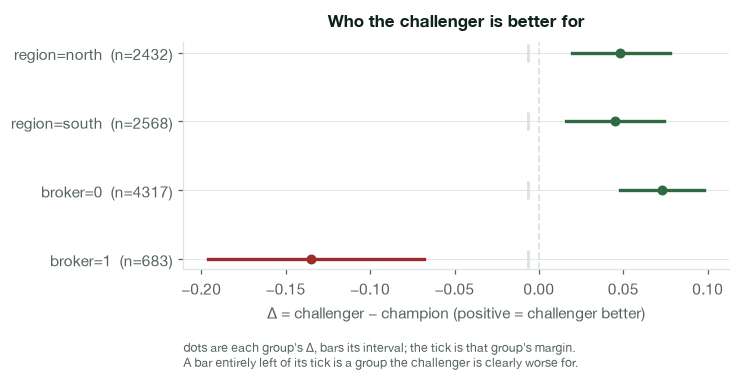

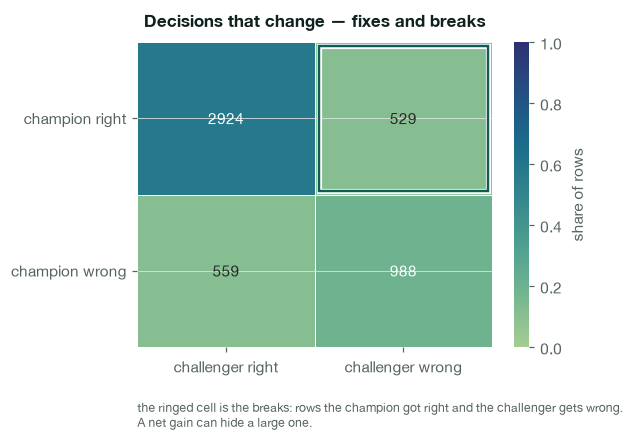

In [8]:
by_name = {c.name: c for c in default_structured_checks(config)}
context = report._context
for name in ("subgroup_regression", "decision_churn"):
    own = [r for r in report.results if r.check_name == name]
    by_name[name].plot(context, own)

## The fix, and the rerun

Restore the dropped rows, retrain, gate again. The challenger is now better
overall by more, no longer worse for brokers, and its changed decisions are
mostly fixes. What is left in the comparison is the two fairness intervals
that cannot rule out a small widening — routed to a person, as they should
be. The `BLOCKED` status is the robustness finding alone.

In [9]:
v4_1 = HistGradientBoostingClassifier(max_iter=200, random_state=0).fit(X_2026, y_2026)
fixed = gate(v4_1, champion)
print(fixed.summary())
comparison_table(fixed)

Gate status: BLOCKED (33580ms, binary)
  roc_auc: 0.7304
  vs champion: roc_auc 0.7304 against 0.6517, Δ +0.0786 [+0.0614, +0.0955] -> improved
  validation: 0 flag(s)
  comparison: 2 flag(s)
  performance: 0 flag(s)
  compliance: 0 flag(s)
  security: 1 flag(s)
  fairness: 0 flag(s)


,check,flag,,detail
0,comparison_integrity,OK,,"champion scorecard_v3.joblib (joblib, sha256 a..."
1,challenger_performance,OK,,"roc_auc (higher is better): challenger 0.7304,..."
2,challenger_guardrails,OK,,"brier: challenger 0.1884, champion 0.2018, Δ +..."
3,subgroup_regression,OK,,region: no group is materially worse off. Wors...
4,subgroup_regression,OK,,broker: no group is materially worse off. Wors...
5,fairness_delta,UNCERTAIN,,region: demographic parity difference challeng...
6,fairness_delta,UNCERTAIN,,region: equal opportunity (TPR) gap challenger...
7,decision_churn,OK,,21.5% of decisions change: 12.5% fixed (champi...
8,operational_delta,NOT_APPLICABLE,,no matching operational measurements — supply ...


## Trap 1 — the same labels, encoded the other way round

A team that encoded *repaid* as the positive class hands over a champion whose
probabilities point the opposite way. Compared naively, the challenger looks
like an enormous improvement — a confident, wrong answer. The integrity check
catches it and **blocks**, because every number after it would be meaningless.

In [10]:
inverted = LogisticRegression(max_iter=2000).fit(X_2025[V3_FEATURES], 1 - y_2025)
blocked = gate(v4_1, Champion(inverted, features=V3_FEATURES))
print(blocked.gate_status)
print(next(r.detail for r in blocked.results if r.check_name == "comparison_integrity"))

BLOCKED
the champion's scores rank y_true backwards (AUC 0.348, against the challenger's 0.730) — its positive class is almost certainly encoded the other way round


## Trap 2 — a pickle from an older library version

The champion was saved under last year's scikit-learn. Unpickling across
versions either fails or, worse, **warns and loads a subtly different model**.
Here the same scorecard is saved as though by scikit-learn 1.3.2.

In [11]:
old_path = registry / "scorecard_v3_saved_with_1.3.2.joblib"
with mock.patch.object(sklearn.base, "__version__", "1.3.2"):
    joblib.dump(v3, old_path)

try:
    Champion.from_file(old_path)
except GateConfigurationError as exc:
    print(exc)

scorecard_v3_saved_with_1.3.2.joblib loaded with a version warning — InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.3.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations. A model unpickled under a different library version may load and behave differently, and a comparison against the wrong champion is worse than none. Score the champion in the environment it was trained in and pass the result as Champion(predictions=...) — or --champion-col on the command line. Scores computed on the same rows are exactly as valid for every comparison check except the operational one.


A warning is not good enough for a governance record, so it is an error, and
the message names the way out: score the champion **in its own environment**
and hand over the predictions. Predictions on the same rows are exactly as
valid for every comparison check except the operational one.

In [12]:
# In the champion's own environment, on the same rows:
scored_in_old_environment = v3.predict_proba(X_val[V3_FEATURES])[:, 1]

from_predictions = gate(v4_1, Champion(predictions=scored_in_old_environment, name="v3 (scored)"))
print(from_predictions.summary().splitlines()[2])

  vs champion: roc_auc 0.7304 against 0.6517, Δ +0.0786 [+0.0614, +0.0955] -> improved


## Trap 3 — an artifact that is not the one approved

Someone retrains v3 in place and overwrites the registry file. A pinned hash
refuses it — and refuses it **before unpickling**, so the unknown bytes never
run.

In [13]:
joblib.dump(LogisticRegression(max_iter=2000).fit(X_2026[V3_FEATURES], y_2026), v3_path)
try:
    Champion.from_file(v3_path, sha256=approved_sha256)
except GateConfigurationError as exc:
    print(exc)
_ = joblib.dump(v3, v3_path)  # put the approved one back

scorecard_v3.joblib does not match its pinned sha256: expected a2716189c89ec760f49b658ae29026b01e4cdc9d849e333643339be5995f741f, found 2fd4e5087a123e623a864948304e08820801d568f082f892969d9ec2502ce43d. Nothing was loaded — a pinned artifact that has changed is not the champion that was approved, and unpickling unknown bytes runs code.


## Would the champion pass today?

`gate_champion=True` also runs the absolute checks against the champion and
reports its verdict beside the challenger's. **Informational only — it never
changes the status.** Its point is the finding *"the incumbent would itself be
blocked today"*, which belongs in front of anyone arguing a challenger is too
risky to replace it.

Here the champion comes back `NEEDS_REVIEW`: its own AUC interval straddles the
0.65 floor, so even the model in production today cannot show that it clears
the bar this gate sets.

In [14]:
both = GateConfig(
    performance=PerformanceConfig(metric="roc_auc", min_score=0.65),
    comparison=ComparisonConfig(gate_champion=True),
)
side_by_side = gate(v4_1, Champion.from_file(v3_path, sha256=approved_sha256), config=both)
print("challenger:", side_by_side.gate_status)
print("champion:  ", side_by_side.champion_report.gate_status)
side_by_side.comparison["champion_gate"]

challenger: BLOCKED
champion:   NEEDS_REVIEW


{'gate_status': 'NEEDS_REVIEW',
 'findings': [{'check_name': 'performance_thresholds', 'flag': 'UNCERTAIN'}]}

## From the command line

The same comparison in a pipeline. `--champion-sha256` pins the registry file;
exit codes are unchanged — `0` pass, `2` needs review, `1` blocked. This one
exits `1`, for the robustness finding above.

In [15]:
from bdp_model_gate.cli import main

work = Path(tempfile.mkdtemp(prefix="gate-"))
X_val.assign(defaulted=y_val).to_csv(work / "validation.csv", index=False)
protected_val.to_csv(work / "protected.csv", index=False)
joblib.dump(v4_1, work / "scorecard_v4.joblib")

exit_code = main(
    [
        "--model", str(work / "scorecard_v4.joblib"),
        "--champion", str(v3_path),
        "--champion-sha256", approved_sha256,
        "--data", str(work / "validation.csv"),
        "--target-col", "defaulted",
        "--protected", str(work / "protected.csv"),
        "--metric", "roc_auc",
        "--min-score", "0.65",
        "--task", "binary",
        "--output", str(work / "gate_report.json"),
    ]
)
print("exit code", exit_code)

05:00:58 INFO     bdp_model_gate.champion: loaded champion scorecard_v3.joblib (joblib, sha256 a2716189c89e…, pinned)


05:01:14 INFO     bdp_model_gate.gate: gate_status=BLOCKED task=binary n_flags=3 metric=roc_auc score=0.7304


Gate status: BLOCKED (16954ms, binary)
  roc_auc: 0.7304
  vs champion: roc_auc 0.7304 against 0.6517, Δ +0.0786 [+0.0614, +0.0955] -> improved
  validation: 0 flag(s)
  comparison: 2 flag(s)
  performance: 0 flag(s)
  compliance: 0 flag(s)
  security: 1 flag(s)
  fairness: 0 flag(s)
Full report written to /var/folders/b0/2m_10_k95pv414965fb1ndjr0000gn/T/gate-dzsu1wny/gate_report.json
exit code 1


## What to take away

- **The challenger still runs the full gate.** The comparison is added on
  top; "better than what we had" is never a pass by itself.
- **Same rows, one interval on the difference.** The champion is re-scored on
  this validation set, and a paired bootstrap makes a real improvement
  visible where two overlapping intervals would have called it a draw.
- **Non-inferior by default.** A retrain that is not measurably better is a
  legitimate replacement; `require="superior"` is there for change processes
  that say otherwise.
- **Better on average is where the review starts.** Subgroups, disparities,
  churn and cost route to a person — the broker channel here is exactly the
  finding a single AUC hides.
- **The traps fail loudly.** An inverted encoding blocks, a version-drifted
  pickle refuses to load, and a pinned hash is checked before a byte is
  unpickled.

See [Replacing a model](https://vanjy-eng.github.io/model-gate/docs/comparison/)
for the reference.